In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yasserh/housing-prices-dataset/Housing.csv


--- Dataset Shape (Rows, Columns) ---
(545, 13)

--- First 5 Rows ---


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



--- Missing Values Per Column ---
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

--- Data Types & Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 n

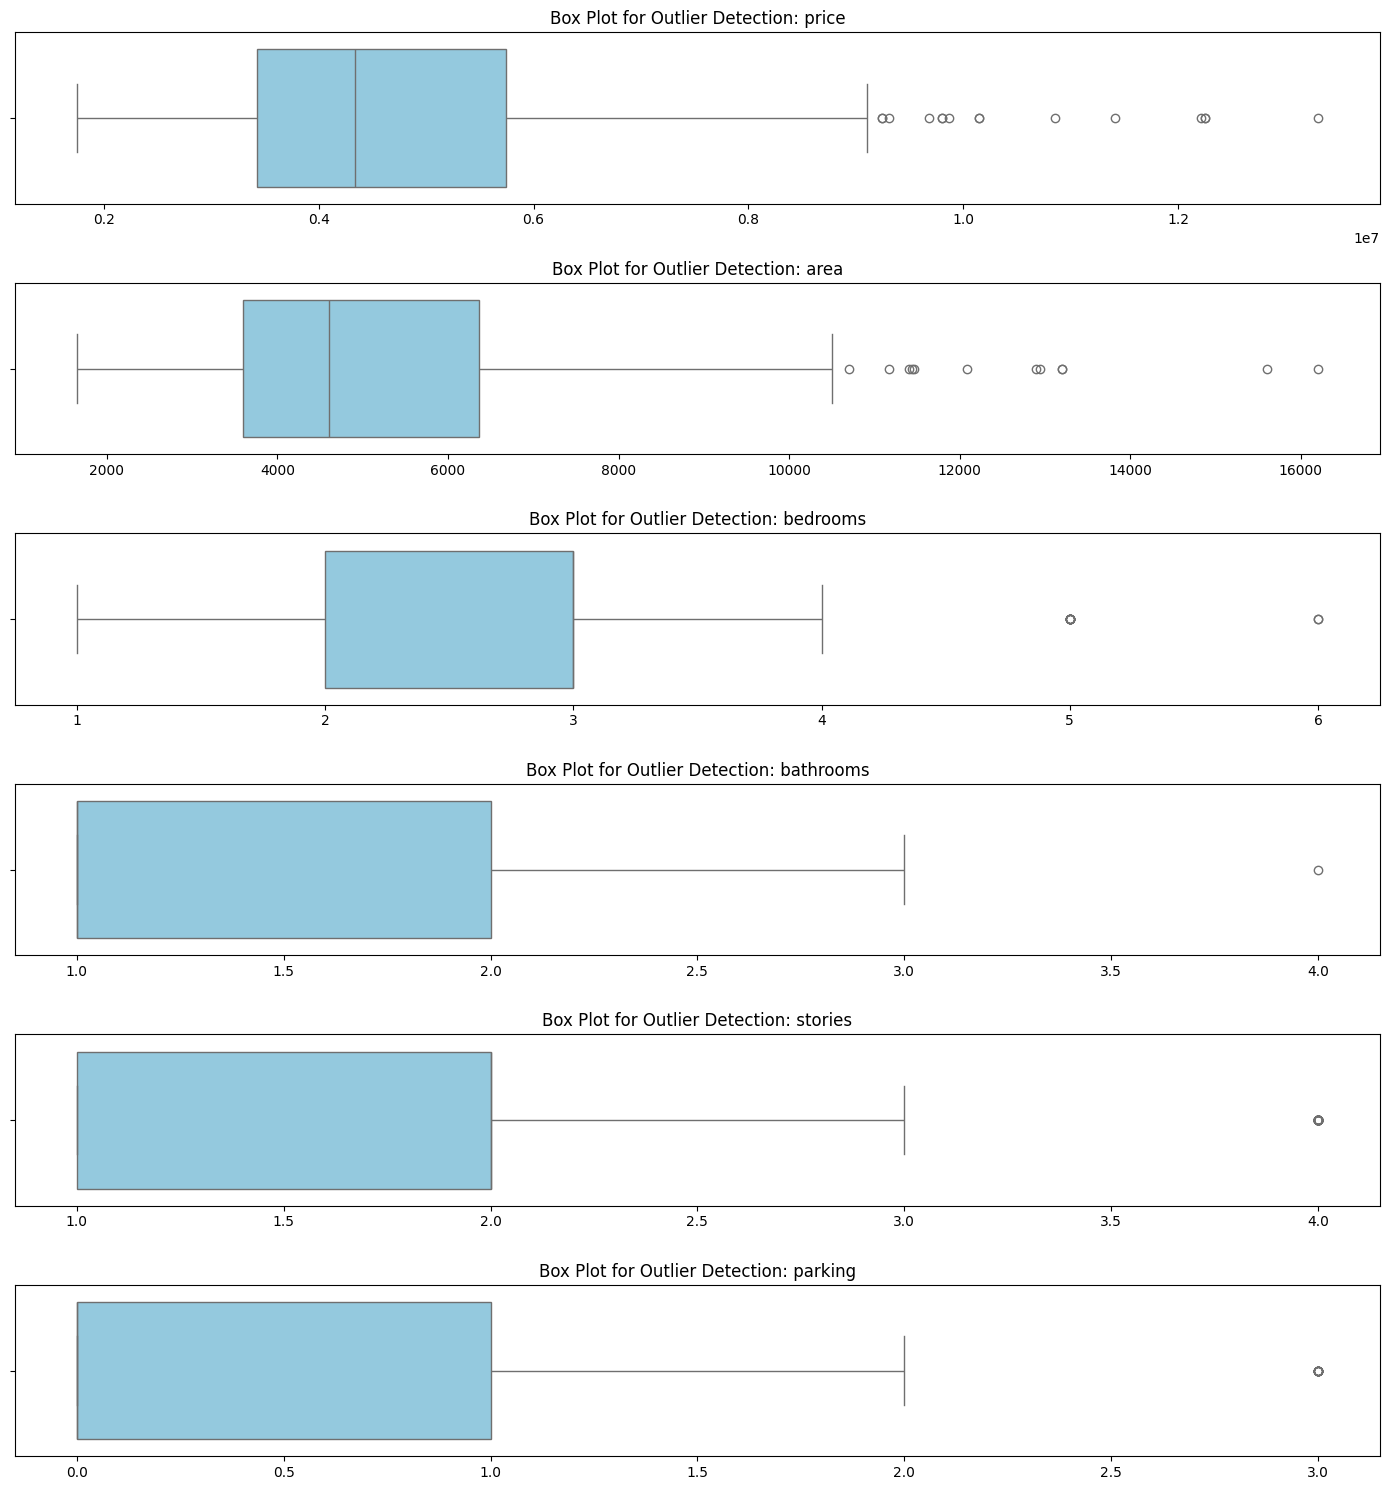

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('/kaggle/input/datasets/yasserh/housing-prices-dataset/Housing.csv')

# 2. Show size and head
print('--- Dataset Shape (Rows, Columns) ---')
print(df.shape)

print('\n--- First 5 Rows ---')
display(df.head())

# 3. Check for null or missing values
print('\n--- Missing Values Per Column ---')
print(df.isnull().sum())

# 4. Inspect data types and unique values for categorical/wrong value checks
print('\n--- Data Types & Info ---')
df.info()

# 5. Plot outliers for numerical columns using box plots
numerical_cols = df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(14, len(numerical_cols) * 2.5))
for i, col in enumerate(numerical_cols, 1):
  plt.subplot(len(numerical_cols), 1, i)
  sns.boxplot(x=df[col], color='skyblue')
  plt.title(f'Box Plot for Outlier Detection: {col}')
  plt.xlabel('')

plt.tight_layout()
plt.show()

================ Logistic Regression ================

Confusion Matrix:
[[32  6  1]
 [ 6 16  4]
 [ 0 10 34]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.82      0.83        39
           1       0.50      0.62      0.55        26
           2       0.87      0.77      0.82        44

    accuracy                           0.75       109
   macro avg       0.74      0.74      0.73       109
weighted avg       0.77      0.75      0.76       109



================ Random Forest Classifier ================

Confusion Matrix:
[[30  9  0]
 [ 8 14  4]
 [ 1 13 30]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.77      0.77        39
           1       0.39      0.54      0.45        26
           2       0.88      0.68      0.77        44

    accuracy                           0.68       109
   macro avg       0.68      0.66      0.66       109
weighted avg      

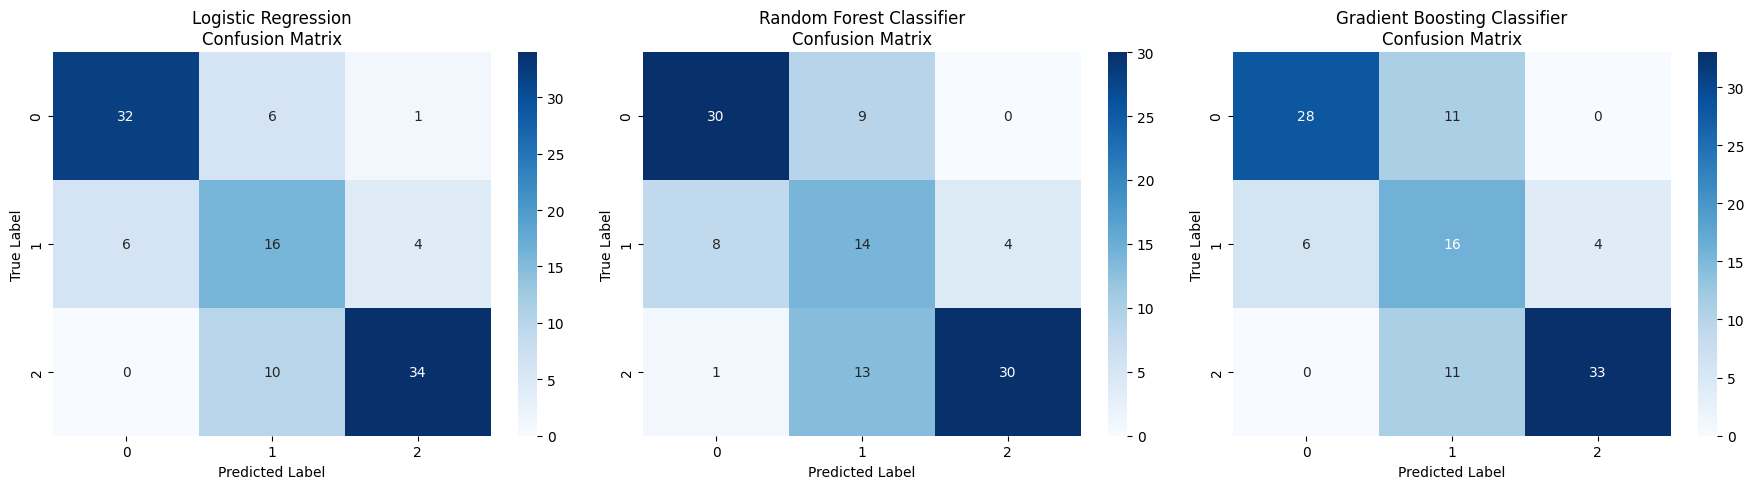

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Prepare Target Variable: Bin 'price' into 3 categories (0: Low, 1: Medium, 2: High)
df['price_category'] = pd.qcut(df['price'], q=3, labels=[0, 1, 2])

# Separate features (X) and target (y)
X = df.drop(['price', 'price_category'], axis=1)
y = df['price_category']

# 2. Preprocessing: Apply One-Hot Encoding to categorical columns
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

# 4. Feature Scaling (helpful for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Define Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(random_state=42),
    'Gradient Boosting Classifier': GradientBoostingClassifier(random_state=42),
}

# 6. Train, Evaluate, and Plot Confusion Matrices
fig, axes = plt.subplots(1, len(models), figsize=(18, 5))

for i, (name, model) in enumerate(models.items()):
  # Train model
  model.fit(X_train_scaled, y_train)

  # Predictions
  y_pred = model.predict(X_test_scaled)

  print(f'================ {name} ================\n')
  print('Confusion Matrix:')
  cm = confusion_matrix(y_test, y_pred)
  print(cm)

  print('\nClassification Report:')
  print(classification_report(y_test, y_pred))
  print('\n' + '=' * 50 + '\n')

  # Plot Confusion Matrix using Seaborn heatmap
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
  axes[i].set_title(f'{name}\nConfusion Matrix')
  axes[i].set_xlabel('Predicted Label')
  axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()